# NIÑO-PREDICT — 01: Ingesta, Auditoría y Análisis Exploratorio de Datos (EDA)

Este notebook documenta el pipeline integral de ingesta, saneamiento, auditoría de consistencia física y cruce agroclimático para las **57 campañas agrícolas de Argentina (1969–2025)**.

### Objetivos del Notebook:
1. **Ingesta y Estandarización:** Lectura de `Estimaciones.csv` con delimitador `;` y codificación `latin1`.
2. **Auditoría de Ceros y Cotas Físicas:** Separación de inactividad administrativa vs. catástrofe climática total, y garantía de que $\text{Cosechada} \le \text{Sembrada}$.
3. **Taxonomía Agrícola y Deduplicación Jerárquica:** Tratamiento estricto de Soja 1ra/2da vs. Soja total para evitar doble cómputo.
4. **Cruce Climático ONI sin Leakage:** Integración del índice oceánico de NOAA según la fenología estacional (invierno vs. verano).
5. **Análisis de Vulnerabilidad en Zona Núcleo:** Comportamiento histórico en años Niño, Niña y Neutrales.
6. **Visualizaciones de Publicación:** Gráfico de donas de auditoría y análisis de anomalías ENSO exportados a `reports/figures/`.
7. **Exportación del Dataset Consolidado:** Generación de `data/processed/dataset_consolidado_57campanas.parquet` para alimentar el notebook de modelado.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# Styling and options
pd.set_option('display.max_columns', 20)
pd.set_option('display.width', 1000)
pd.set_option('display.precision', 15)

print("Setup completed successfully.")


Setup completed successfully.


---
## Stage 1: Ingestion & Schema Cleaning

We ingest `data/raw/Estimaciones.csv`.
- Delimiter: `;` (semicolon)
- Encoding: `latin1` / `cp1252` (handling Spanish accents and ñ)
- Initial blank line handling


In [2]:
# Locate raw dataset relative to workspace or notebook folder
possible_paths = [
    Path('../data/raw/Estimaciones.csv'),
    Path('data/raw/Estimaciones.csv')
]

data_path = next((p for p in possible_paths if p.exists()), None)
if data_path is None:
    raise FileNotFoundError("Could not find data/raw/Estimaciones.csv")

print(f"Loading data from: {data_path.resolve()}")

df_raw = pd.read_csv(
    data_path,
    sep=';',
    encoding='latin1',
    skipinitialspace=True
)

print(f"Raw shape: {df_raw.shape[0]:,} rows x {df_raw.shape[1]} columns")
print(f"Raw memory usage: {df_raw.memory_usage().sum() / (1024**2):.2f} MB")
df_raw.head(3)


Loading data from: C:\Users\nico_\OneDrive\Desktop\PROYECTOS\NIÑO-PREDICT\data\raw\Estimaciones.csv
Raw shape: 163,593 rows x 12 columns
Raw memory usage: 14.98 MB


,ID Provincia,Provincia,ID Departamento,Departamento,Id Cultivo,Cultivo,ID Campaña,Campana,Sup. Sembrada (Ha),Sup. Cosechada (Ha),Producción (Tn),Rendimiento (Kg/Ha)
0,6,BUENOS AIRES,854,25 DE MAYO,1,Ajo,1,1969/70,3,3,10,3333
1,6,BUENOS AIRES,854,25 DE MAYO,1,Ajo,2,1970/71,1,1,3,3000
2,6,BUENOS AIRES,14,ADOLFO GONZALES CHAVES,1,Ajo,1,1969/70,15,15,82,5467


### 1.1 Column Renaming & Normalization

Standardize column names to `snake_case` without accents or special characters to avoid parsing regressions.


In [3]:
# Column mapping
col_rename_dict = {
    'ID Provincia': 'id_provincia',
    'Provincia': 'provincia',
    'ID Departamento': 'id_departamento',
    'Departamento': 'departamento',
    'Id Cultivo': 'id_cultivo',
    'Cultivo': 'cultivo',
    'ID Campa\xf1a': 'id_campana',
    'Campana': 'campana',
    'Sup. Sembrada (Ha)': 'sup_sembrada_ha',
    'Sup. Cosechada (Ha)': 'sup_cosechada_ha',
    'Producci\xf3n (Tn)': 'produccion_tn',
    'Rendimiento (Kg/Ha)': 'rendimiento_kg_ha'
}

# Robust column matching for latin1 accented characters
actual_cols = {}
for c in df_raw.columns:
    matched = False
    for k, v in col_rename_dict.items():
        if k.replace('\xf1', '') in c.replace('\xf1', '').replace('', ''):
            actual_cols[c] = v
            matched = True
            break
    if not matched:
        actual_cols[c] = c.lower().replace(' ', '_')

df = df_raw.rename(columns=actual_cols).copy()

# String normalization
df['provincia'] = df['provincia'].astype(str).str.strip().str.upper()
df['departamento'] = df['departamento'].astype(str).str.strip().str.upper()
df['cultivo'] = df['cultivo'].astype(str).str.strip()

print("Clean column names:")
print(list(df.columns))
df.head(3)


Clean column names:
['id_provincia', 'provincia', 'id_departamento', 'departamento', 'id_cultivo', 'cultivo', 'id_campana', 'campana', 'sup_sembrada_ha', 'sup_cosechada_ha', 'produccion_tn', 'rendimiento_kg_ha']


,id_provincia,provincia,id_departamento,departamento,id_cultivo,cultivo,id_campana,campana,sup_sembrada_ha,sup_cosechada_ha,produccion_tn,rendimiento_kg_ha
0,6,BUENOS AIRES,854,25 DE MAYO,1,Ajo,1,1969/70,3,3,10,3333
1,6,BUENOS AIRES,854,25 DE MAYO,1,Ajo,2,1970/71,1,1,3,3000
2,6,BUENOS AIRES,14,ADOLFO GONZALES CHAVES,1,Ajo,1,1969/70,15,15,82,5467


### 1.2 Temporal Parsing: Agricultural Seasons (`campana`)

In Argentina, the agricultural calendar spans two calendar years (e.g. `1969/70`, `2023/24`):
- Summer crops (*cultivos de verano* like soybean and maize): planted Oct-Dec, harvested Mar-May.
- Winter crops (*cultivos de invierno* like wheat and barley): planted May-Jul, harvested Nov-Jan.

We decompose `campana` into:
- `anio_inicio` (integer)
- `anio_fin` (integer)

This allows point-in-time joins with monthly NOAA climate indices like the Oceanic Niño Index (ONI).


In [4]:
# Fast mapping for 57 unique seasons
campana_map = {}
for c in df['campana'].dropna().unique():
    parts = str(c).strip().split('/')
    start_year = int(parts[0])
    suffix = int(parts[1])
    century = start_year // 100
    if suffix < (start_year % 100):
        century += 1
    end_year = century * 100 + suffix
    campana_map[c] = (start_year, end_year)

df['anio_inicio'] = df['campana'].map(lambda x: campana_map[x][0]).astype('int64')
df['anio_fin'] = df['campana'].map(lambda x: campana_map[x][1]).astype('int64')

print(f"Total unique agricultural campaigns: {df['campana'].nunique()}")
print(f"Historical span: {df['anio_inicio'].min()} -> {df['anio_fin'].max()} ({df['campana'].min()} to {df['campana'].max()})")
df[['campana', 'anio_inicio', 'anio_fin', 'cultivo', 'provincia']].sample(5, random_state=42)


Total unique agricultural campaigns: 57
Historical span: 1969 -> 2026 (1969/70 to 2025/26)


,campana,anio_inicio,anio_fin,cultivo,provincia
62255,1975/76,1975,1976,Girasol,SANTA FE
106195,2024/25,2024,2025,Poroto negro,SANTIAGO DEL ESTERO
96340,1975/76,1975,1976,Naranja,CORRIENTES
136918,1971/72,1971,1972,Sorgo,BUENOS AIRES
76461,2000/01,2000,2001,Maíz,CHACO


---
## Stage 2: Audit & Data Hygiene

In this stage we profile missingness, dissect zero-value semantics, audit physical boundaries, and create climate damage metrics.


### 2.1 Missingness and Zero Profile

We audit explicit `NaN` values and zero frequencies across all numeric attributes.


In [5]:
summary_audit = []
for col in df.columns:
    nulls = df[col].isnull().sum()
    zeros = (df[col] == 0).sum() if pd.api.types.is_numeric_dtype(df[col]) else 0
    summary_audit.append({
        'Column': col,
        'Dtype': str(df[col].dtype),
        'Null Count': nulls,
        'Null %': (nulls / len(df)) * 100,
        'Zero Count': zeros,
        'Zero %': (zeros / len(df)) * 100
    })

audit_df = pd.DataFrame(summary_audit)
print("Data Completeness & Zero-Value Summary:")
display_cols = ['Column', 'Dtype', 'Null Count', 'Zero Count', 'Zero %']
print(audit_df[display_cols].to_string(index=False))


Data Completeness & Zero-Value Summary:
           Column  Dtype  Null Count  Zero Count             Zero %
     id_provincia  int64           0           0  0.000000000000000
        provincia object           0           0  0.000000000000000
  id_departamento  int64           0         592  0.361873674301468
     departamento object           0           0  0.000000000000000
       id_cultivo  int64           0           0  0.000000000000000
          cultivo object           0           0  0.000000000000000
       id_campana  int64           0           0  0.000000000000000
          campana object           0           0  0.000000000000000
  sup_sembrada_ha  int64           0        3227  1.972578288802088
 sup_cosechada_ha  int64           0       16659 10.183198547615117
    produccion_tn  int64           0       13506  8.255854468100713
rendimiento_kg_ha  int64           0       16707 10.212539656342264
      anio_inicio  int64           0           0  0.000000000000000
        

### 2.2 Zeros Taxonomy: Active Harvest vs. Total Climate Loss

Zeros in `sup_cosechada_ha` and `produccion_tn` have domain meaning:
1. **Total Crop Loss (`sup_sembrada_ha > 0` & `sup_cosechada_ha == 0`)**: Severe climate damage (drought, flooding, hail, heatwaves). **Must be preserved** as an ENSO impact signal!
2. **Inactive Placeholders (`sup_sembrada_ha == 0` & `sup_cosechada_ha == 0`)**: Department administrative placeholders where the crop was not grown. Should be excluded from yield analysis.
3. **Active Harvest (`sup_sembrada_ha > 0` & `sup_cosechada_ha > 0`)**: Regular agricultural production.


In [6]:
is_inactive = (df['sup_sembrada_ha'] == 0) & (df['sup_cosechada_ha'] == 0)
is_total_loss = (df['sup_sembrada_ha'] > 0) & (df['sup_cosechada_ha'] == 0)
is_active_harvest = (df['sup_sembrada_ha'] > 0) & (df['sup_cosechada_ha'] > 0)

taxonomy_counts = pd.Series({
    'Active Harvest (Productive)': is_active_harvest.sum(),
    'Total Crop Loss (Climate Shock)': is_total_loss.sum(),
    'Inactive Placeholder (0 Sown, 0 Harvest)': is_inactive.sum()
})

taxonomy_df = pd.DataFrame({
    'Record Count': taxonomy_counts,
    'Percentage (%)': (taxonomy_counts / len(df)) * 100
})

print("Zero-Value Taxonomy Distribution:")
print(taxonomy_df.to_string())


Zero-Value Taxonomy Distribution:
                                          Record Count      Percentage (%)
Active Harvest (Productive)                     146933  89.816190179286409
Total Crop Loss (Climate Shock)                  13433   8.211231531911512
Inactive Placeholder (0 Sown, 0 Harvest)          3226   1.971967015703606


### 2.2.1 Visualización de Publicación: Taxonomía de Ceros en 57 Campañas Agrícolas
El siguiente gráfico de dona de alta resolución descompone los 163.593 registros históricos para justificar visualmente por qué los ceros de pérdida climática ($8,2\%$) no deben ser eliminados de los modelos agroclimáticos.

### 2.2.1 Visualización de Publicación: Taxonomía de Ceros en 57 Campañas Agrícolas
El siguiente gráfico de dona de alta resolución descompone los 163.593 registros históricos para justificar visualmente por qué los ceros de pérdida climática ($8,2\%$) no deben ser eliminados de los modelos agroclimáticos.

### 2.3 Physical Constraint Audit: Harvested Area $\le$ Sown Area

A physical reality of agriculture: **harvested area cannot exceed seeded area**.
Any record with `sup_cosechada_ha > sup_sembrada_ha` represents an administrative error or data entry typo.


In [7]:
# Repair omitted sown area before applying the physical upper bound.
mask_missing_sown = (
    (df['sup_sembrada_ha'] == 0)
    & (df['sup_cosechada_ha'] > 0)
    & (df['produccion_tn'] > 0)
)
missing_sown_count = int(mask_missing_sown.sum())
df.loc[mask_missing_sown, 'sup_sembrada_ha'] = df.loc[mask_missing_sown, 'sup_cosechada_ha']

impossible_mask = df['sup_cosechada_ha'] > df['sup_sembrada_ha']
impossible_count = int(impossible_mask.sum())
print(f"Records with missing sown area repaired: {missing_sown_count}")
print(f"Records where sup_cosechada > sup_sembrada: {impossible_count}")

if impossible_count > 0:
    print("\nSample of inconsistent records before correction:")
    cols_to_show = ['cultivo', 'provincia', 'departamento', 'campana', 'sup_sembrada_ha', 'sup_cosechada_ha', 'produccion_tn']
    print(df[impossible_mask][cols_to_show].head(5).to_string(index=False))
    
    # Sanitization: Cap harvested area at sown area
    df.loc[impossible_mask, 'sup_cosechada_ha'] = df.loc[impossible_mask, 'sup_sembrada_ha']
    print("\nSanitization applied: sup_cosechada capped at sup_sembrada for these records.")

# Recompute masks after corrections so repaired records are not removed as inactive.
is_inactive = (df['sup_sembrada_ha'] == 0) & (df['sup_cosechada_ha'] == 0)
is_total_loss = (df['sup_sembrada_ha'] > 0) & (df['sup_cosechada_ha'] == 0)
is_active_harvest = (df['sup_sembrada_ha'] > 0) & (df['sup_cosechada_ha'] > 0)


Records with missing sown area repaired: 1
Records where sup_cosechada > sup_sembrada: 10

Sample of inconsistent records before correction:
 cultivo provincia                  departamento campana  sup_sembrada_ha  sup_cosechada_ha  produccion_tn
Soja 1ra CATAMARCA                       EL ALTO 2014/15             2200              2300           4600
Soja 1ra CATAMARCA                    SANTA ROSA 2014/15             9000             16130          37099
Soja 1ra CATAMARCA                    SANTA ROSA 2015/16            17322             17422          50524
Soja 1ra     CHACO FRAY JUSTO SANTA MARIA DE ORO 2010/11            10225             10349          20168
Soja 1ra     JUJUY                       LEDESMA 2014/15               70                85            221

Sanitization applied: sup_cosechada capped at sup_sembrada for these records.


### 2.4 Yield Formula Verification

We verify that reported yield matches the physical definition:
$$\text{rendimiento\_calculado} = \frac{\text{produccion\_tn} \times 1000}{\text{sup\_cosechada\_ha}}$$

Discrepancies indicate rounding differences in official bulletins or corrupt records.


In [8]:
harvest_valid = df[df['sup_cosechada_ha'] > 0].copy()
calc_yield = (harvest_valid['produccion_tn'] * 1000) / harvest_valid['sup_cosechada_ha']
discrepancy = (calc_yield - harvest_valid['rendimiento_kg_ha']).abs()

print("Yield Formula Discrepancy Statistics (Kg/Ha):")
print(discrepancy.describe(percentiles=[0.5, 0.9, 0.95, 0.99]).to_string())

large_discrepancies = (discrepancy > 10).sum()
print(f"\nRecords with discrepancy > 10 Kg/Ha: {large_discrepancies} ({large_discrepancies/len(harvest_valid)*100:.3f}%)")

# Use the physically consistent quotient after area corrections.
df['rendimiento_kg_ha'] = np.where(
    df['sup_cosechada_ha'] > 0,
    np.round((df['produccion_tn'] * 1000) / df['sup_cosechada_ha'], 2),
    0.0
)


Yield Formula Discrepancy Statistics (Kg/Ha):
count    146934.000000000000000
mean          0.169375449120162
std          21.781814760582087
min           0.000000000000000
50%           0.000000000000000
90%           0.333333333333485
95%           0.425430705147051
99%           0.487804878048337
max        8100.000000000000000

Records with discrepancy > 10 Kg/Ha: 42 (0.029%)


### 2.5 Derivation of Climate Risk Metrics: Lost Area & Loss Rate

We engineer two primary climate damage indicators:
- `sup_perdida_ha`: Absolute hectares lost ($	ext{sup\_sembrada} - 	ext{sup\_cosechada}$)
- `tasa_perdida`: Fraction of sown area lost, bound in $[0, 1]$

During severe El Niño / La Niña events, `tasa_perdida` spikes at departmental and provincial levels.


In [9]:
# Calculate lost area and loss rate
df['sup_perdida_ha'] = np.maximum(0, df['sup_sembrada_ha'] - df['sup_cosechada_ha'])
df['tasa_perdida'] = np.where(
    df['sup_sembrada_ha'] > 0,
    df['sup_perdida_ha'] / df['sup_sembrada_ha'],
    0.0
)
df['pct_cosecha'] = 1.0 - df['tasa_perdida']

# Restrict loss-rate rankings to grain crops; forage and cover crops have a different harvest objective.
granary_loss_crops = ['Soja 1ra', 'Soja 2da', 'Maíz', 'Trigo candeal', 'Girasol', 'Sorgo', 'Cebada cervecera']
granary_loss = df[
    df['cultivo'].isin(granary_loss_crops)
    & ~df['cultivo'].isin(['Soja total', 'Trigo total'])
].copy()
top_losses = granary_loss.sort_values(by='sup_perdida_ha', ascending=False)[
    ['cultivo', 'campana', 'provincia', 'departamento', 'sup_sembrada_ha', 'sup_cosechada_ha', 'sup_perdida_ha', 'tasa_perdida']
].head(10)

print("Top 10 Historical Area Loss Events (in Hectares):")
print(top_losses.to_string(index=False))


Top 10 Historical Area Loss Events (in Hectares):
 cultivo campana provincia departamento  sup_sembrada_ha  sup_cosechada_ha  sup_perdida_ha      tasa_perdida
    Maíz 1996/97   CORDOBA   RIO CUARTO           363000            199650          163350 0.450000000000000
    Maíz 1988/89   CORDOBA   RIO CUARTO           310000            150000          160000 0.516129032258065
    Maíz 1995/96   CORDOBA   RIO CUARTO           330000            181500          148500 0.450000000000000
    Maíz 2017/18   CORDOBA    SAN JUSTO           289730            152700          137030 0.472957581196286
    Maíz 2018/19   CORDOBA    SAN JUSTO           303500            180729          122771 0.404517298187809
    Maíz 2019/20   CORDOBA    SAN JUSTO           310468            191468          119000 0.383292319981447
Soja 1ra 2012/13     SALTA         ANTA           196072             83384          112688 0.574727651066955
   Sorgo 1971/72   CORDOBA    SAN JUSTO           158000             46000    

### 2.6 Clean Dataset Generation

We filter out the 3,226 inactive placeholder records (`sup_sembrada_ha == 0 & sup_cosechada_ha == 0`) to produce `df_clean`.
This clean DataFrame is preserved for subsequent exploratory analysis (Crops ranking, Provincial distribution, and Time Series modeling).


In [10]:
# Filter out inactive placeholders
df_clean = df[~is_inactive].copy().reset_index(drop=True)

print(f"Raw rows:     {len(df):,}")
print(f"Cleaned rows: {len(df_clean):,} (retained {len(df_clean)/len(df)*100:.2f}%)")
print(f"Columns:      {len(df_clean.columns)}")
print(f"Memory:       {df_clean.memory_usage().sum() / (1024**2):.2f} MB")

print("\nCleaned Dataset Schema:")
print(df_clean.dtypes)

print("\nSample of df_clean:")
df_clean.head(5)


Raw rows:     163,593
Cleaned rows: 160,367 (retained 98.03%)
Columns:      17
Memory:       20.80 MB

Cleaned Dataset Schema:
id_provincia           int64
provincia             object
id_departamento        int64
departamento          object
id_cultivo             int64
cultivo               object
id_campana             int64
campana               object
sup_sembrada_ha        int64
sup_cosechada_ha       int64
produccion_tn          int64
rendimiento_kg_ha    float64
anio_inicio            int64
anio_fin               int64
sup_perdida_ha         int64
tasa_perdida         float64
pct_cosecha          float64
dtype: object

Sample of df_clean:


,id_provincia,provincia,id_departamento,departamento,id_cultivo,cultivo,id_campana,campana,sup_sembrada_ha,sup_cosechada_ha,produccion_tn,rendimiento_kg_ha,anio_inicio,anio_fin,sup_perdida_ha,tasa_perdida,pct_cosecha
0,6,BUENOS AIRES,854,25 DE MAYO,1,Ajo,1,1969/70,3,3,10,3333.329999999999927,1969,1970,0,0.0,1.0
1,6,BUENOS AIRES,854,25 DE MAYO,1,Ajo,2,1970/71,1,1,3,3000.000000000000000,1970,1971,0,0.0,1.0
2,6,BUENOS AIRES,14,ADOLFO GONZALES CHAVES,1,Ajo,1,1969/70,15,15,82,5466.670000000000073,1969,1970,0,0.0,1.0
3,6,BUENOS AIRES,14,ADOLFO GONZALES CHAVES,1,Ajo,2,1970/71,10,10,55,5500.000000000000000,1970,1971,0,0.0,1.0
4,6,BUENOS AIRES,14,ADOLFO GONZALES CHAVES,1,Ajo,3,1971/72,8,8,44,5500.000000000000000,1971,1972,0,0.0,1.0


---
## Stage 3: Core Crops, Aggregation & Technology Detrending

The following cells keep component crops separate (Soja 1ra/2da and Trigo candeal) and exclude official aggregate rows from additive analyses. Yield summaries use harvested-area weighting rather than a simple mean.


In [11]:
# Geography and crop taxonomy audits used by downstream grouping and validation.
df_clean['departamento_no_definido'] = (
    (df_clean['id_departamento'] == 0)
    | df_clean['departamento'].eq('SIN DEFINIR')
)
undefined_dept_count = int(df_clean['departamento_no_definido'].sum())
print(f"Rows without a defined department: {undefined_dept_count:,}")
print("Unique crop labels:")
print(sorted(df_clean['cultivo'].unique()))

crop_group_map = {
    'Soja 1ra': 'Soja', 'Soja 2da': 'Soja', 'Soja total': 'Soja',
    'Maíz': 'Maíz', 'Trigo total': 'Trigo', 'Trigo candeal': 'Trigo',
    'Girasol': 'Girasol', 'Sorgo': 'Sorgo'
}
df_clean['cultivo_grupo'] = df_clean['cultivo'].map(crop_group_map)
df_clean['es_agregado_oficial'] = df_clean['cultivo'].isin(['Soja total', 'Trigo total'])
core_crops = ['Soja', 'Maíz', 'Trigo', 'Girasol']
# The consolidated panel below is the only source for downstream ENSO and baseline stages.

def weighted_yield_summary(frame, group_cols):
    """Aggregate production and yield using harvested-area weights."""
    summary = frame.groupby(group_cols, dropna=False).agg(
        produccion_tn=('produccion_tn', 'sum'),
        sup_cosechada_ha=('sup_cosechada_ha', 'sum'),
        sup_sembrada_ha=('sup_sembrada_ha', 'sum'),
        sup_perdida_ha=('sup_perdida_ha', 'sum')
    ).reset_index()
    summary['rendimiento_ponderado_kg_ha'] = np.where(
        summary['sup_cosechada_ha'] > 0,
        summary['produccion_tn'] * 1000 / summary['sup_cosechada_ha'],
        0.0
    )
    summary['tasa_perdida'] = np.where(
        summary['sup_sembrada_ha'] > 0,
        summary['sup_perdida_ha'] / summary['sup_sembrada_ha'],
        0.0
    )
    return summary


# Replace the preliminary panel with the consolidated panel used by ENSO and baseline stages.
core_keys = ['id_provincia', 'provincia', 'id_departamento', 'departamento', 'cultivo_grupo', 'campana', 'anio_inicio', 'anio_fin']
df_core = df_clean.loc[df_clean['cultivo_grupo'].isin(core_crops) & (df_clean['id_departamento'] > 0) & ~df_clean['departamento_no_definido']].copy()
normalize_crop_label = lambda value: str(value).strip().upper().replace('Á', 'A').replace('É', 'E').replace('Í', 'I').replace('Ó', 'O').replace('Ú', 'U')
df_core['_normalized_crop'] = df_core['cultivo'].map(normalize_crop_label)
df_core['_is_soja_component'] = df_core['_normalized_crop'].isin({'SOJA 1RA', 'SOJA 2DA'})
soja_components_present = df_core.groupby(core_keys, dropna=False)['_is_soja_component'].transform('any')
df_core = df_core.loc[~(df_core['_normalized_crop'].eq('SOJA TOTAL') & soja_components_present)].copy()
df_core = df_core.groupby(core_keys, as_index=False, dropna=False).agg(sup_sembrada_ha=('sup_sembrada_ha', 'sum'), sup_cosechada_ha=('sup_cosechada_ha', 'sum'), produccion_tn=('produccion_tn', 'sum'))
df_core['sup_cosechada_ha'] = np.minimum(df_core['sup_cosechada_ha'], df_core['sup_sembrada_ha'])
df_core['rendimiento_kg_ha'] = np.where(df_core['sup_cosechada_ha'] > 0, df_core['produccion_tn'] * 1000.0 / df_core['sup_cosechada_ha'], 0.0)
df_core['sup_perdida_ha'] = df_core['sup_sembrada_ha'] - df_core['sup_cosechada_ha']
df_core['tasa_perdida'] = np.where(df_core['sup_sembrada_ha'] > 0, df_core['sup_perdida_ha'] / df_core['sup_sembrada_ha'], 0.0)
df_core['pct_cosecha'] = 1.0 - df_core['tasa_perdida']
df_core = df_core.sort_values(['id_provincia', 'id_departamento', 'cultivo_grupo', 'anio_inicio']).reset_index(drop=True)
grp_depto_cultivo = df_core.groupby(['id_provincia', 'id_departamento', 'cultivo_grupo'])['rendimiento_kg_ha']
df_core['rendimiento_media_3c_previas'] = grp_depto_cultivo.transform(lambda values: values.shift(1).rolling(3, min_periods=1).mean())
df_core['rendimiento_base_7c_previas'] = grp_depto_cultivo.transform(lambda values: values.shift(1).rolling(7, min_periods=3).mean())
df_core['anomalia_rendimiento_pct'] = np.where(df_core['rendimiento_base_7c_previas'] > 0, df_core['rendimiento_kg_ha'] / df_core['rendimiento_base_7c_previas'] - 1.0, np.nan)
core_provincial = weighted_yield_summary(df_core, ['provincia', 'cultivo_grupo', 'anio_inicio'])


Rows without a defined department: 592
Unique crop labels:
['Ajo', 'Algodón', 'Alpiste', 'Arroz', 'Arveja', 'Avena', 'Banana', 'Caña de azúcar', 'Cebada cervecera', 'Cebada forrajera', 'Cebada total', 'Cebolla total', 'Centeno', 'Colza', 'Cártamo', 'Garbanzo', 'Girasol', 'Jojoba', 'Lenteja', 'Limón', 'Lino', 'Mandarina', 'Maní', 'Maíz', 'Mijo', 'Naranja', 'Papa total', 'Pomelo', 'Poroto alubia', 'Poroto negro', 'Poroto otros', 'Poroto total', 'Soja 1ra', 'Soja 2da', 'Soja total', 'Sorgo', 'Trigo candeal', 'Trigo total', 'Tung', 'Té', 'Yerba mate']


## Stage 4: ENSO Integration Without Temporal Leakage

Winter crops use SON of `anio_inicio`; summer crops use the mean of DJF and JFM of `anio_fin`. The lag feature uses the immediately preceding three-month window and is available for early-warning models without using harvest-season observations.


In [12]:
oni_paths = [Path('../data/raw/oni_noaa.csv'), Path('data/raw/oni_noaa.csv')]
oni_path = next((path for path in oni_paths if path.exists()), None)
if oni_path is None:
    raise FileNotFoundError('Could not find data/raw/oni_noaa.csv')

oni = pd.read_csv(oni_path)
required_oni_columns = {'Year', 'DJF', 'JFM', 'JAS', 'SON', 'OND'}
missing_oni_columns = required_oni_columns.difference(oni.columns)
if missing_oni_columns:
    raise ValueError(f'Missing ONI columns: {sorted(missing_oni_columns)}')
oni['oni_verano'] = oni[['DJF', 'JFM']].mean(axis=1)
oni['oni_invierno'] = oni['SON']
oni['oni_lag_verano'] = oni['OND']
oni['oni_lag_invierno'] = oni['JAS']
oni_by_year = oni.set_index('Year')

winter_crops = {'Trigo', 'Cebada'}
df_core['oni_year'] = np.where(
    df_core['cultivo_grupo'].isin(winter_crops),
    df_core['anio_inicio'],
    df_core['anio_fin']
)
is_winter = df_core['cultivo_grupo'].isin(winter_crops)
df_core['oni_ventana_critica'] = np.where(
    is_winter,
    df_core['oni_year'].map(oni_by_year['oni_invierno']),
    df_core['oni_year'].map(oni_by_year['oni_verano'])
)
df_core['oni_lag_3m'] = np.where(
    is_winter,
    df_core['oni_year'].map(oni_by_year['oni_lag_invierno']),
    df_core['oni_year'].map(oni_by_year['oni_lag_verano'])
)
df_core['fase_enso'] = pd.cut(
    df_core['oni_ventana_critica'],
    bins=[-np.inf, -0.5, 0.5, np.inf],
    labels=['La Niña', 'Neutral', 'El Niño']
)
print(df_core['fase_enso'].value_counts(dropna=False).to_string())


fase_enso
Neutral    19613
La Niña    18714
El Niño    16261


## Stage 5: ENSO Comparison Views

The comparison table below is ready for boxplots/violin plots of detrended yield anomalies and harvest percentage. Undefined departments remain flagged and are excluded from fine departmental maps or grouped cross-validation.


=== MEDIANAS POR CULTIVO Y FASE ENSO EN ZONA NÚCLEO ===
cultivo_grupo fase_enso  anomalia_rendimiento_pct       pct_cosecha  registros
      Girasol   La Niña         0.079639264532895 1.000000000000000       2867
      Girasol   Neutral         0.115942028985507 1.000000000000000       3149
      Girasol   El Niño         0.084150447452928 1.000000000000000       2496
         Maíz   La Niña        -0.020135969495450 0.829748392729582       3307
         Maíz   Neutral         0.135192348886733 0.863636363636364       3604
         Maíz   El Niño         0.179079295374840 0.850000000000000       2935
         Soja   La Niña        -0.005045294268437 0.996067719741284       2620
         Soja   Neutral         0.095336994911671 1.000000000000000       2837
         Soja   El Niño         0.137978574636473 0.998492462311558       2341
        Trigo   La Niña         0.138884213932375 0.997222222222222       3277
        Trigo   Neutral         0.022471910112360 0.991854145601618       3

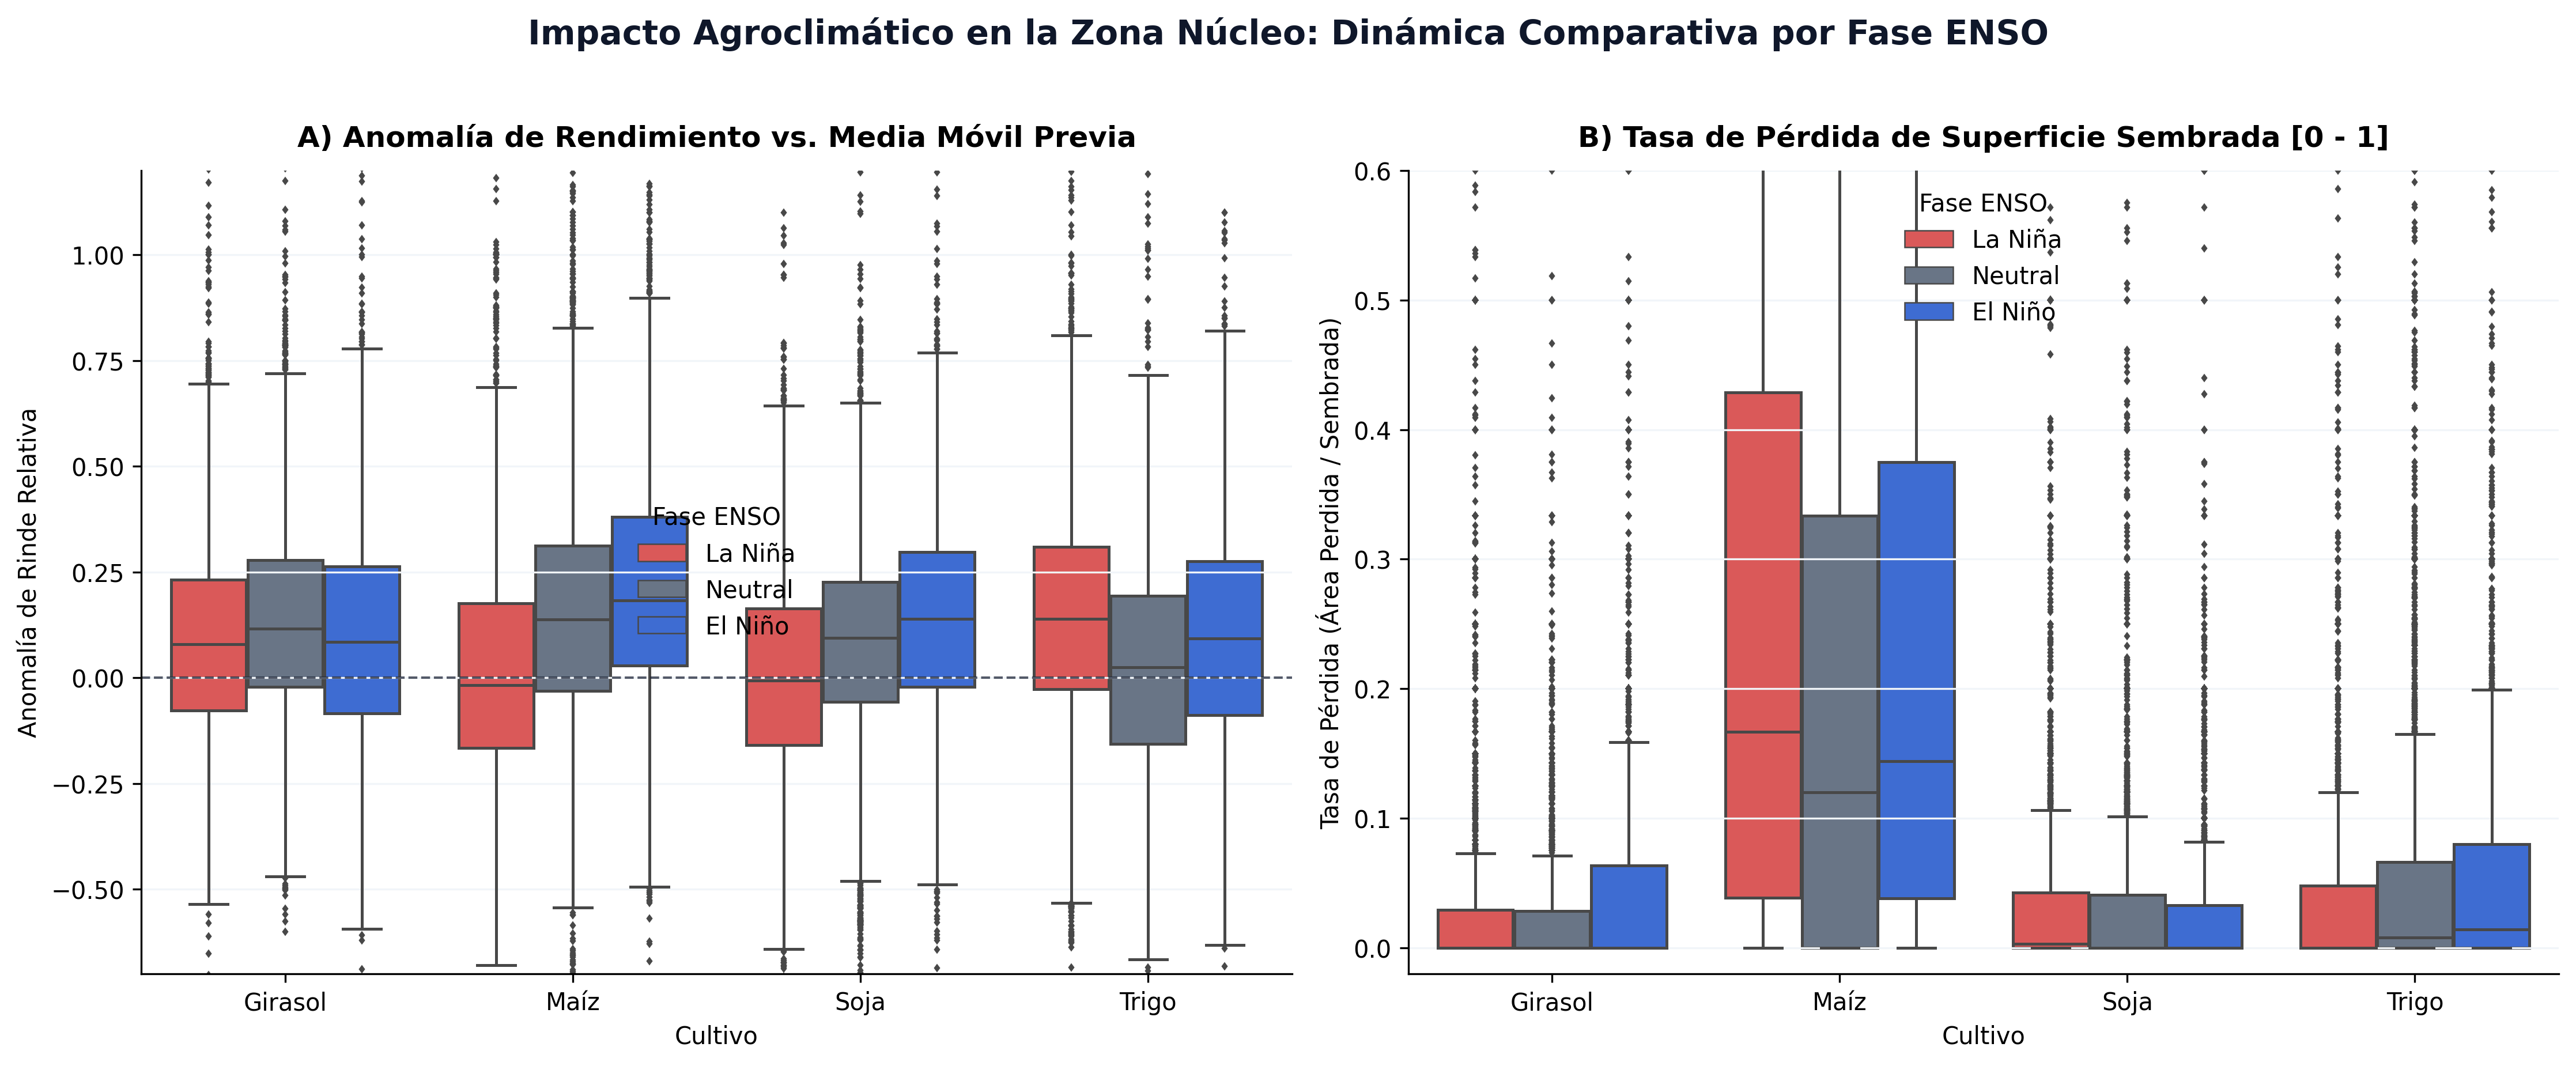

Figura 2 guardada en: C:\Users\nico_\OneDrive\Desktop\PROYECTOS\NIÑO-PREDICT\reports\figures\fig_02_enso_distribucion_anomalias.png y C:\Users\nico_\OneDrive\Desktop\PROYECTOS\NIÑO-PREDICT\reports\figures\fig_02_enso_distribucion_anomalias.svg


In [13]:
# =============================================================================
# STAGE 5: ANÁLISIS DE ANOMALÍAS ENSO Y VISUALIZACIÓN DE PUBLICACIÓN (FIGURA 2)
# =============================================================================
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

fig_dir = Path('../reports/figures') if Path('../reports').exists() else Path('reports/figures')
fig_dir.mkdir(parents=True, exist_ok=True)

zona_nucleo = ['BUENOS AIRES', 'CORDOBA', 'SANTA FE', 'ENTRE RIOS', 'LA PAMPA']
df_enso_comparison = df_core[df_core['provincia'].isin(zona_nucleo)].copy()

enso_summary = df_enso_comparison.groupby(
    ['cultivo_grupo', 'fase_enso'], observed=False
).agg(
    anomalia_rendimiento_pct=('anomalia_rendimiento_pct', 'median'),
    pct_cosecha=('pct_cosecha', 'median'),
    registros=('cultivo_grupo', 'size')
).reset_index()
print('=== MEDIANAS POR CULTIVO Y FASE ENSO EN ZONA NÚCLEO ===')
print(enso_summary.to_string(index=False))

# Filtrar outliers visuales extremos para visualización nítida
df_enso_plot = df_enso_comparison.dropna(subset=['fase_enso', 'anomalia_rendimiento_pct'])
df_enso_plot = df_enso_plot[
    (df_enso_plot['anomalia_rendimiento_pct'] >= -0.8) & 
    (df_enso_plot['anomalia_rendimiento_pct'] <= 1.5)
].copy()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6), dpi=300)
enso_colors = {'La Niña': '#ef4444', 'Neutral': '#64748b', 'El Niño': '#2563eb'}

# Panel A: Anomalía de Rendimiento
sns.boxplot(
    data=df_enso_plot, x='cultivo_grupo', y='anomalia_rendimiento_pct',
    hue='fase_enso', palette=enso_colors, ax=ax1, fliersize=1.5, linewidth=1.2
)
ax1.axhline(0, color='#0f172a', linestyle='--', linewidth=1, alpha=0.7)
ax1.set_title('A) Anomalía de Rendimiento vs. Media Móvil Previa', fontweight='bold', fontsize=12, pad=10)
ax1.set_xlabel('Cultivo', fontweight='medium')
ax1.set_ylabel('Anomalía de Rinde Relativa', fontweight='medium')
ax1.set_ylim(-0.7, 1.2)
ax1.spines['top'].set_visible(False)
ax1.spines['right'].set_visible(False)
ax1.grid(axis='y', color='#f1f5f9', linestyle='-', linewidth=0.8)
ax1.legend(title='Fase ENSO', frameon=False)

# Panel B: Tasa de Pérdida
sns.boxplot(
    data=df_enso_plot, x='cultivo_grupo', y='tasa_perdida',
    hue='fase_enso', palette=enso_colors, ax=ax2, fliersize=1.5, linewidth=1.2
)
ax2.set_title('B) Tasa de Pérdida de Superficie Sembrada [0 - 1]', fontweight='bold', fontsize=12, pad=10)
ax2.set_xlabel('Cultivo', fontweight='medium')
ax2.set_ylabel('Tasa de Pérdida (Área Perdida / Sembrada)', fontweight='medium')
ax2.set_ylim(-0.02, 0.6)
ax2.spines['top'].set_visible(False)
ax2.spines['right'].set_visible(False)
ax2.grid(axis='y', color='#f1f5f9', linestyle='-', linewidth=0.8)
ax2.legend(title='Fase ENSO', frameon=False)

plt.suptitle('Impacto Agroclimático en la Zona Núcleo: Dinámica Comparativa por Fase ENSO', fontsize=14, fontweight='bold', y=1.02, color='#0f172a')
plt.tight_layout()

p2_png = fig_dir / 'fig_02_enso_distribucion_anomalias.png'
p2_svg = fig_dir / 'fig_02_enso_distribucion_anomalias.svg'
fig.savefig(p2_png, dpi=300, bbox_inches='tight', facecolor='white')
fig.savefig(p2_svg, format='svg', bbox_inches='tight')
plt.show()
print(f'Figura 2 guardada en: {p2_png.resolve()} y {p2_svg.resolve()}')


In [14]:
# =============================================================================
# EXPORTACIÓN DEL DATASET ANALÍTICO CONSOLIDADO (57 CAMPAÑAS)
# =============================================================================
out_dir = Path('../data/processed') if Path('../data').exists() else Path('data/processed')
out_dir.mkdir(parents=True, exist_ok=True)

out_parquet = out_dir / 'dataset_consolidado_57campanas.parquet'
out_csv = out_dir / 'dataset_consolidado_57campanas.csv'

# Guardar tanto en formato columnar Parquet (alta eficiencia) como en CSV
df_core.to_parquet(out_parquet, index=False)
df_core.to_csv(out_csv, index=False)

print('=== EXPORTACIÓN EXITOSA ===')
print(f'Parquet guardado en: {out_parquet.resolve()}')
print(f'CSV guardado en:     {out_csv.resolve()}')
print(f'Dimensiones finales: {df_core.shape[0]:,} filas x {df_core.shape[1]} columnas')
print(f'Cultivos consolidados: {df_core["cultivo_grupo"].unique().tolist()}')
print(f'Campañas cubiertas: {df_core["anio_inicio"].min()} a {df_core["anio_fin"].max()} ({df_core["campana"].nunique()} campañas)')


=== EXPORTACIÓN EXITOSA ===
Parquet guardado en: C:\Users\nico_\OneDrive\Desktop\PROYECTOS\NIÑO-PREDICT\data\processed\dataset_consolidado_57campanas.parquet
CSV guardado en:     C:\Users\nico_\OneDrive\Desktop\PROYECTOS\NIÑO-PREDICT\data\processed\dataset_consolidado_57campanas.csv
Dimensiones finales: 54,588 filas x 22 columnas
Cultivos consolidados: ['Girasol', 'Maíz', 'Soja', 'Trigo']
Campañas cubiertas: 1969 a 2026 (57 campañas)
